# CSE464 Case Study 1 – Sales KPI Review for a UK Online Gift Retailer

**Course:** CSE464 – Introduction to Data Science & Big Data Analytics (Fall 2026)
**Student:** Kenan Saleh (20220702115)
**Dataset:** UCI Online Retail, ID 352 (Chen, 2015), DOI [10.24432/C5BW33](https://doi.org/10.24432/C5BW33)
**Selected issue:** 1(b)(ii) – sales figures / company KPIs are below expectations.

**Time-series question.** *Across complete calendar months, when did net invoiced sales fall most relative to the
preceding month, which countries accounted for the change, and what should management investigate first?*

"Fall most" = the largest absolute month-to-month decline in GBP. The percentage change is reported separately.
The preceding complete month is used only as a **historical benchmark** – the company's real targets, costs and
margins are not in the data, so invoiced sales are never treated as profit.

The notebook follows the nine steps of the course hand-out. It runs top to bottom in a fresh Google Colab
runtime (Runtime ▸ Run all). It needs no Drive mount; it downloads the data from UCI and writes charts and a
results file to a relative `outputs/` folder.

In [1]:
# Setup: install the official UCI import package if it is missing (Colab does not ship it).
import importlib.util, subprocess, sys
if importlib.util.find_spec("ucimlrepo") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"], check=True)

import json, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

OUT = Path("outputs"); FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# Chart style: light print palette, thin marks, recessive grid
BLUE, BLUE_LIGHT, ORANGE, RED, GRAY = "#2a78d6", "#9ec5f4", "#eb6834", "#e34948", "#898781"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 11,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
def money(v, dp=0):
    # GBP with the sign in front: money(-1234.5) -> '−£1,235'
    return f"{'−' if v < 0 else ''}£{abs(v):,.{dp}f}"

gbp_k = FuncFormatter(lambda v, _: f"{'−' if v < 0 else ''}£{abs(v)/1000:,.0f}k")

R = {}  # every number used in the report is stored here and saved to outputs/results.json

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

print("Python", platform.python_version(), "| pandas", pd.__version__, "| NumPy", np.__version__,
      "| matplotlib", matplotlib.__version__)

Python 3.13.18 | pandas 3.0.5 | NumPy 2.5.3 | matplotlib 3.11.2


## Step 1 – Load the data

The hand-out asks for the UC Irvine Python import, so the primary route is `fetch_ucirepo(id=352)`.
The loader checks that both ID fields (`InvoiceNo`, `StockCode`) and all six feature columns came back.
If the package fails or omits a field, it falls back to UCI's official Excel workbook
(`online+retail.zip`), and if the network is unavailable it reads a local copy of that workbook
(`data/Online Retail.xlsx`). No synthetic or sample data is ever used.

In [2]:
EXPECTED = ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID", "Country"]
WORKBOOK_URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
LOCAL_WORKBOOK = Path("data") / "Online Retail.xlsx"

def load_online_retail(use_ucimlrepo=True):
    # Returns (raw DataFrame, source description, metadata dict or None)
    if use_ucimlrepo:
        try:
            from ucimlrepo import fetch_ucirepo
            repo = fetch_ucirepo(id=352)
            print("Returned object keys:", list(repo.keys()))
            print("repo.data keys:     ", list(repo.data.keys()))
            print("ids columns:        ", list(repo.data.ids.columns))
            print("features columns:   ", list(repo.data.features.columns))
            print("targets:            ", repo.data.targets)
            original = repo.data.original
            missing = [c for c in EXPECTED if c not in original.columns]
            if missing:
                raise ValueError(f"fetch_ucirepo omitted essential fields: {missing}")
            return original[EXPECTED].copy(), f"fetch_ucirepo(id=352) -> {repo.metadata['data_url']}", repo.metadata
        except Exception as err:
            print("Official Python import failed, using the UCI workbook instead:", repr(err))
    try:
        import io, urllib.request, zipfile
        with urllib.request.urlopen(WORKBOOK_URL, timeout=180) as resp:
            archive = zipfile.ZipFile(io.BytesIO(resp.read()))
        xlsx_name = [n for n in archive.namelist() if n.lower().endswith(".xlsx")][0]
        LOCAL_WORKBOOK.parent.mkdir(exist_ok=True)
        LOCAL_WORKBOOK.write_bytes(archive.read(xlsx_name))
        source = f"UCI official workbook {WORKBOOK_URL} ({xlsx_name})"
    except Exception as err:
        print("Workbook download failed:", repr(err))
        if not LOCAL_WORKBOOK.exists():
            raise FileNotFoundError(f"No network access and no local copy at {LOCAL_WORKBOOK}. "
                                    "Download online+retail.zip from the UCI page and unzip it there.")
        source = f"local copy of the UCI workbook: {LOCAL_WORKBOOK}"
    # dtype=str keeps alphanumeric codes such as 'C536379' and '85123A' intact
    frame = pd.read_excel(LOCAL_WORKBOOK, dtype={"InvoiceNo": str, "StockCode": str})
    return frame[EXPECTED].copy(), source, None

raw, SOURCE, meta = load_online_retail()
# Keep the identifiers as text exactly as published (strip stray spaces only)
for col in ["InvoiceNo", "StockCode"]:
    raw[col] = raw[col].astype(str).str.strip()

if meta is not None:
    print("\nDataset:", meta["name"], "| UCI id:", meta["uci_id"], "| DOI:", meta["dataset_doi"])
    print("Characteristics:", meta["characteristics"], "| instances listed by UCI:", meta["num_instances"])
    print("Summary:", meta["additional_info"]["summary"])
print("\nSource used:", SOURCE)
print("Raw rows (invoice lines):", f"{len(raw):,}", "| columns:", list(raw.columns))
_dates = (raw["InvoiceDate"] if pd.api.types.is_datetime64_any_dtype(raw["InvoiceDate"])
          else pd.to_datetime(raw["InvoiceDate"], format="%m/%d/%Y %H:%M"))
print("Date range:", _dates.min(), "to", _dates.max())
R["source"] = SOURCE
R["raw_rows"] = int(len(raw))
R["date_min"], R["date_max"] = str(_dates.min()), str(_dates.max())

Returned object keys: ['data', 'metadata', 'variables']
repo.data keys:      ['ids', 'features', 'targets', 'original', 'headers']
ids columns:         ['InvoiceNo', 'StockCode']
features columns:    ['Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
targets:             None

Dataset: Online Retail | UCI id: 352 | DOI: 10.24432/C5BW33
Characteristics: ['Multivariate', 'Sequential', 'Time-Series'] | instances listed by UCI: 541909
Summary: This is a transactional data set which contains all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.The company mainly sells unique all-occasion gifts. Many customers of the company are wholesalers.

Source used: fetch_ucirepo(id=352) -> https://archive.ics.uci.edu/static/public/352/data.csv
Raw rows (invoice lines): 541,909 | columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Date range: 20

## Step 2 – Understand the dataset

One row is an **invoice line**: one product (`StockCode`) on one invoice (`InvoiceNo`). An invoice can contain many
lines, so line counts and invoice counts are always reported separately.

In [3]:
print("Shape (rows, columns):", raw.shape)
display(raw.head(5))
print("\ndata.dtypes")
print(raw.dtypes)

Shape (rows, columns): (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom



data.dtypes
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object


In [4]:
print("data.describe() – numeric columns as loaded")
display(raw.describe())
print("data.describe() – text columns")
display(raw.select_dtypes(exclude="number").describe())

data.describe() – numeric columns as loaded


,Quantity,UnitPrice,CustomerID
count,"541,909.00","541,909.00","406,829.00"
mean,9.55,4.61,"15,287.69"
std,218.08,96.76,"1,713.60"
min,"-80,995.00","-11,062.06","12,346.00"
25%,1.00,1.25,"13,953.00"
50%,3.00,2.08,"15,152.00"
75%,10.00,4.13,"16,791.00"
max,"80,995.00","38,970.00","18,287.00"


data.describe() – text columns


,InvoiceNo,StockCode,Description,InvoiceDate,Country
count,541909,541909,540455,541909,541909
unique,25900,4070,4223,23260,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,10/31/2011 14:41,United Kingdom
freq,1114,2313,2369,1114,495478


In [5]:
field_info = pd.DataFrame([
    ["InvoiceNo",   "Identifier (text)",      "Invoice number; a leading 'C' marks a cancellation/credit note"],
    ["StockCode",   "Identifier (text)",      "Product code; a few codes are services (POST, DOT, M, AMAZONFEE ...)"],
    ["Description", "Category (text)",        "Product name"],
    ["Quantity",    "Numeric measure (units)", "Units on the line; negative on credit notes"],
    ["InvoiceDate", "Date-time",              "Day and time the invoice was generated"],
    ["UnitPrice",   "Numeric measure (GBP)",  "Price per unit in pounds sterling"],
    ["CustomerID",  "Identifier (stored as a number)", "Customer number; blank for some transactions"],
    ["Country",     "Category (text)",        "Country where the customer resides"],
], columns=["Field", "Type", "Meaning (UCI variable information)"])
display(field_info)

missing = pd.DataFrame({"missing": raw.isna().sum(), "missing_%": (raw.isna().mean() * 100).round(2)})
display(missing)
lines_per_invoice = raw.groupby("InvoiceNo").size()
print(f"Invoice lines: {len(raw):,} | unique invoices: {raw['InvoiceNo'].nunique():,} | "
      f"unique products: {raw['StockCode'].nunique():,} | known customers: {raw['CustomerID'].nunique():,} | "
      f"countries: {raw['Country'].nunique()}")
print(f"Lines per invoice: median {lines_per_invoice.median():.0f}, mean {lines_per_invoice.mean():.1f}, max {lines_per_invoice.max():,}")
R["missing_customer"] = int(raw["CustomerID"].isna().sum())
R["missing_description"] = int(raw["Description"].isna().sum())
R["raw_invoices"] = int(raw["InvoiceNo"].nunique())
R["raw_countries"] = int(raw["Country"].nunique())
R["lines_per_invoice_median"] = float(lines_per_invoice.median())

,Field,Type,Meaning (UCI variable information)
0,InvoiceNo,Identifier (text),Invoice number; a leading 'C' marks a cancella...
1,StockCode,Identifier (text),"Product code; a few codes are services (POST, ..."
2,Description,Category (text),Product name
3,Quantity,Numeric measure (units),Units on the line; negative on credit notes
4,InvoiceDate,Date-time,Day and time the invoice was generated
5,UnitPrice,Numeric measure (GBP),Price per unit in pounds sterling
6,CustomerID,Identifier (stored as a number),Customer number; blank for some transactions
7,Country,Category (text),Country where the customer resides


,missing,missing_%
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Invoice lines: 541,909 | unique invoices: 25,900 | unique products: 4,070 | known customers: 4,372 | countries: 38
Lines per invoice: median 10, mean 20.9, max 1,114


**Observations.** `InvoiceDate` is loaded as text and must be parsed. `CustomerID` is an identifier stored as a
float, so its mean/std in `describe()` have no meaning. `Quantity` and `UnitPrice` both have negative minimums,
which points to credit notes and adjustments (Step 3). UCI's metadata says "no missing values", but the actual
counts show missing `CustomerID` and `Description` values, so the real counts are used.

## Step 3 – Clean the data

Checks: repeated header, data types, missing values, repeated rows, cancellations, negative quantities, unusual
prices and non-merchandise codes. Every row gets a single, first-matching exclusion reason so that
**raw = retained + excluded** can be verified.

In [6]:
df = raw.copy()
# 3.1 Repeated header rows (a header line accidentally stored as data)
header_rows = (df["InvoiceNo"] == "InvoiceNo").sum()
print("Repeated header rows found:", header_rows, "-> nothing to remove" if header_rows == 0 else "")
df = df[df["InvoiceNo"] != "InvoiceNo"].copy()

# 3.2 Parse types; codes stay as text
if not pd.api.types.is_datetime64_any_dtype(df["InvoiceDate"]):
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%m/%d/%Y %H:%M")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce").astype("Int64")
for col in ["Description", "Country"]:
    df[col] = df[col].astype("string").str.strip()
print("Unparseable dates / quantities / prices:",
      int(df["InvoiceDate"].isna().sum()), int(df["Quantity"].isna().sum()), int(df["UnitPrice"].isna().sum()))
print(df.dtypes)

Repeated header rows found: 0 -> nothing to remove


Unparseable dates / quantities / prices: 0 0 0
InvoiceNo                 str
StockCode                 str
Description            string
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID              Int64
Country                string
dtype: object


In [7]:
# 3.3 Missing values: where are they?
print("Missing Description rows by UnitPrice:", df.loc[df["Description"].isna(), "UnitPrice"].value_counts().to_dict())
print(f"Missing CustomerID rows: {df['CustomerID'].isna().sum():,} (kept if the sales fields are valid)")

# 3.4 Repeated rows: identical in all 8 fields
dup_mask = df.duplicated(keep="first")
print(f"Exact repeated rows (all 8 fields identical, excluding first copy): {dup_mask.sum():,}")
print("Kept: the data has no line number, so two identical lines on the same invoice can be a real double order."
      " Step 6A tests whether removing them changes the conclusion.")

# 3.5 Cancellations and negative quantities
df["IsCredit"] = df["InvoiceNo"].str.startswith("C")
prefix = df["InvoiceNo"].str[0].where(~df["InvoiceNo"].str[0].str.isdigit(), "digit")
print("\nInvoice number prefix counts:", prefix.value_counts().to_dict())
print("Credit-note lines:", f"{df['IsCredit'].sum():,}", "| of which Quantity > 0:", int((df["IsCredit"] & (df["Quantity"] > 0)).sum()))
neg_normal = (~df["IsCredit"]) & (df["Quantity"] < 0)
print(f"Non-credit lines with negative Quantity: {neg_normal.sum():,}; their UnitPrice values:",
      df.loc[neg_normal, "UnitPrice"].value_counts().to_dict())

# 3.6 Unusual prices
print(f"\nUnitPrice == 0: {(df['UnitPrice'] == 0).sum():,} | UnitPrice < 0: {(df['UnitPrice'] < 0).sum():,}")
display(df[df["UnitPrice"] < 0][["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "InvoiceDate"]])
print("Highest unit prices:")
display(df.nlargest(5, "UnitPrice")[["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]])

# 3.7 Extreme quantities: are the huge orders reversed by a matching credit note?
big = df[df["Quantity"].abs() >= 10000][["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "InvoiceDate", "CustomerID"]]
big = big.assign(LineValue=big["Quantity"] * big["UnitPrice"])
display(big)
print("The two priced extreme orders (Jan 2011, Dec 2011) are each cancelled by a credit note for the same product, customer"
      " and quantity within minutes, so each pair nets to zero inside its month. Both sides are kept: removing only one"
      " side would distort net sales. The 12,540-unit line has a zero price and is excluded by rule R1 below.")
R["extreme_orders"] = [{"invoice": r.InvoiceNo, "qty": int(r.Quantity), "value": float(r.LineValue),
                        "date": str(r.InvoiceDate.date())} for r in big.itertuples()]

Missing Description rows by UnitPrice: {0.0: 1454}
Missing CustomerID rows: 135,080 (kept if the sales fields are valid)


Exact repeated rows (all 8 fields identical, excluding first copy): 5,268
Kept: the data has no line number, so two identical lines on the same invoice can be a real double order. Step 6A tests whether removing them changes the conclusion.



Invoice number prefix counts: {'digit': 532618, 'C': 9288, 'A': 3}
Credit-note lines: 9,288 | of which Quantity > 0: 0
Non-credit lines with negative Quantity: 1,336; their UnitPrice values: {0.0: 1336}

UnitPrice == 0: 2,515 | UnitPrice < 0: 2


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate
299983,A563186,B,Adjust bad debt,1,"-11,062.06",2011-08-12 14:51:00
299984,A563187,B,Adjust bad debt,1,"-11,062.06",2011-08-12 14:52:00


Highest unit prices:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice
222681,C556445,M,Manual,-1,"38,970.00"
524602,C580605,AMAZONFEE,AMAZON FEE,-1,"17,836.46"
43702,C540117,AMAZONFEE,AMAZON FEE,-1,"16,888.02"
43703,C540118,AMAZONFEE,AMAZON FEE,-1,"16,453.71"
15016,C537630,AMAZONFEE,AMAZON FEE,-1,"13,541.33"


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate,CustomerID,LineValue
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00,12346,"77,183.60"
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,2011-01-18 10:17:00,12346,"-77,183.60"
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,2011-11-25 15:57:00,13256,0.00
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00,16446,"168,469.60"
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,2011-12-09 09:27:00,16446,"-168,469.60"


The two priced extreme orders (Jan 2011, Dec 2011) are each cancelled by a credit note for the same product, customer and quantity within minutes, so each pair nets to zero inside its month. Both sides are kept: removing only one side would distort net sales. The 12,540-unit line has a zero price and is excluded by rule R1 below.


In [8]:
# 3.8 Non-merchandise codes: postage, fees, manual entries, discounts, samples, bad-debt and gift vouchers
NON_MERCH = {"POST", "DOT", "C2", "M", "m", "D", "S", "BANK CHARGES", "AMAZONFEE", "CRUK", "B"}
is_non_merch = df["StockCode"].isin(NON_MERCH) | df["StockCode"].str.startswith("gift_0001")
df["LineValue"] = df["Quantity"] * df["UnitPrice"]
nm = (df[is_non_merch].groupby("StockCode")
        .agg(lines=("LineValue", "size"), value_gbp=("LineValue", "sum"), example=("Description", "first"))
        .sort_values("lines", ascending=False))
display(nm)

# 3.9 Eligibility rules (first failing rule is the exclusion reason)
valid_sign = ((~df["IsCredit"]) & (df["Quantity"] > 0)) | (df["IsCredit"] & (df["Quantity"] < 0))
df["Exclusion"] = np.select(
    [df["UnitPrice"].isna() | df["Quantity"].isna() | df["InvoiceDate"].isna(),
     df["UnitPrice"] <= 0,
     ~valid_sign,
     is_non_merch],
    ["R0 unparseable field",
     "R1 zero/negative unit price (stock adjustments, bad-debt write-offs)",
     "R2 quantity sign does not match invoice type",
     "R3 non-merchandise code (postage, fees, manual, discount, samples, vouchers)"],
    default="Retained")
recon = df["Exclusion"].value_counts().rename_axis("Rule").to_frame("Invoice lines")
display(recon)

eligible = df[df["Exclusion"] == "Retained"].copy()
n_raw, n_ret = len(raw), len(eligible)
n_exc = int((df["Exclusion"] != "Retained").sum()) + int(header_rows)
assert n_raw == n_ret + n_exc, "Row reconciliation failed"
print(f"Raw {n_raw:,} = retained {n_ret:,} + excluded {n_exc:,}  ✔")
print(f"Retained lines with missing CustomerID: {eligible['CustomerID'].isna().sum():,} "
      f"(GBP {eligible.loc[eligible['CustomerID'].isna(), 'LineValue'].sum():,.0f}) – kept for the aggregate KPI")
print(f"Retained credit-note lines: {eligible['IsCredit'].sum():,} – kept so that returns reduce net sales")
cred_by_rule = df.loc[df["IsCredit"], "Exclusion"].value_counts()
print(f"Credit-note lines: raw {df['IsCredit'].sum():,} = retained {cred_by_rule.get('Retained', 0):,} + excluded "
      f"{df['IsCredit'].sum() - cred_by_rule.get('Retained', 0):,}; by rule:", cred_by_rule.to_dict())
assert df["IsCredit"].sum() == cred_by_rule.sum()
R.update(retained_rows=n_ret, excluded_rows=n_exc,
         excluded_by_rule={k: int(v) for k, v in recon["Invoice lines"].items() if k != "Retained"},
         duplicate_rows=int(dup_mask.sum()), credit_lines_raw=int(df["IsCredit"].sum()),
         retained_credit_lines=int(eligible["IsCredit"].sum()),
         excluded_credit_lines=int(df["IsCredit"].sum() - eligible["IsCredit"].sum()),
         credit_excluded_by_rule={k[:2]: int(v) for k, v in cred_by_rule.items() if k != "Retained"},
         retained_missing_customer=int(eligible["CustomerID"].isna().sum()),
         zero_price=int((df["UnitPrice"] == 0).sum()), negative_price=int((df["UnitPrice"] < 0).sum()),
         neg_qty_noncredit=int(neg_normal.sum()), non_merch_rows=int((df["Exclusion"].str.startswith("R3")).sum()))

,lines,value_gbp,example
StockCode,,,
POST,1256,"66,230.64",POSTAGE
DOT,710,"206,245.48",DOTCOM POSTAGE
M,571,"-68,674.19",Manual
C2,144,"6,986.00",CARRIAGE
D,77,"-5,696.22",Discount
S,63,"-3,049.39",SAMPLES
BANK CHARGES,37,"-7,175.64",Bank Charges
AMAZONFEE,34,"-221,520.50",AMAZON FEE
CRUK,16,"-7,933.43",CRUK Commission


,Invoice lines
Rule,
Retained,536465
"R3 non-merchandise code (postage, fees, manual, discount, samples, vouchers)",2927
"R1 zero/negative unit price (stock adjustments, bad-debt write-offs)",2517


Raw 541,909 = retained 536,465 + excluded 5,444  ✔
Retained lines with missing CustomerID: 131,586 (GBP 1,506,046) – kept for the aggregate KPI
Retained credit-note lines: 8,704 – kept so that returns reduce net sales
Credit-note lines: raw 9,288 = retained 8,704 + excluded 584; by rule: {'Retained': 8704, 'R3 non-merchandise code (postage, fees, manual, discount, samples, vouchers)': 584}


**Eligibility rules (why).**
- **R1** – lines with a zero or negative price are not sales. All 1,454 lines with a missing description, and all
  non-credit lines with a negative quantity, have a price of 0 (they are stock adjustments). The two negative-price
  lines are "Adjust bad debt" accounting entries.
- **R2** – a normal invoice must have a positive quantity and a credit note a negative one. In this data no line
  breaks this rule once R1 is applied, but the rule is kept as a guard.
- **R3** – postage, carriage, bank and Amazon fees, manual entries, discounts, samples, bad-debt adjustments and
  gift vouchers are not merchandise sales. They are excluded from the KPI scope. Step 6A tests putting them back.
- **Kept:** credit notes (they reduce net sales once), lines with no `CustomerID` (the sale is still valid for
  the monthly total) and identical repeated lines (they cannot be proven to be errors).

## Step 4 – Create the selected DataFrame and analyse the target variable Y

**Y = monthly net invoiced sales (GBP)** for merchandise lines that pass R1–R3.
For each line, `LineValue = Quantity × UnitPrice` (signed: credit lines are negative).
Per calendar month (by `InvoiceDate`):

* positive sales = sum of positive line values
* credit magnitude = −(sum of negative line values) – each credit line counted once, in the month it was issued
* **net sales = positive sales − credit magnitude = sum of all signed line values**

Three levels of observation are used: invoice **line** (row), **invoice** (all lines with one `InvoiceNo`) and
**month** (all invoices in a calendar month).

In [9]:
sales = eligible[["InvoiceNo", "StockCode", "InvoiceDate", "Country", "CustomerID",
                  "Quantity", "UnitPrice", "LineValue", "IsCredit"]].copy()
sales["Month"] = sales["InvoiceDate"].dt.to_period("M")
sales["Day"] = sales["InvoiceDate"].dt.normalize()
sales["Region"] = np.where(sales["Country"] == "United Kingdom", "United Kingdom", "International")

# A month is complete only if the data covers it from its first to its last day
cover_start, cover_end = sales["InvoiceDate"].min().normalize(), sales["InvoiceDate"].max()
def is_complete(p):
    return (p.start_time >= cover_start) and (p.end_time <= cover_end)

def monthly_table(frame):
    g = frame.groupby("Month")
    t = pd.DataFrame({
        "lines": g.size(),
        "sales_invoices": frame[~frame["IsCredit"]].groupby("Month")["InvoiceNo"].nunique(),
        "credit_invoices": frame[frame["IsCredit"]].groupby("Month")["InvoiceNo"].nunique(),
        "invoice_days": g["Day"].nunique(),
        "known_customers": g["CustomerID"].nunique(),
        "positive_sales": g["LineValue"].apply(lambda s: s[s > 0].sum()),
        "credit_magnitude": g["LineValue"].apply(lambda s: -s[s < 0].sum()),
        "net_sales": g["LineValue"].sum(),
    })
    t[["sales_invoices", "credit_invoices"]] = t[["sales_invoices", "credit_invoices"]].fillna(0).astype(int)
    t["net_per_invoice_day"] = t["net_sales"] / t["invoice_days"]
    t["complete"] = [is_complete(p) for p in t.index]
    return t

monthly = monthly_table(sales)
assert np.allclose(monthly["positive_sales"] - monthly["credit_magnitude"], monthly["net_sales"])
assert np.isclose(monthly["net_sales"].sum(), sales["LineValue"].sum())
assert monthly["lines"].sum() == len(sales)
print("Checks passed: positive − credit = net for every month; monthly totals = sum of eligible signed line values.")
print(f"Coverage: {cover_start.date()} to {cover_end}")
display(monthly)

Checks passed: positive − credit = net for every month; monthly totals = sum of eligible signed line values.
Coverage: 2010-12-01 to 2011-12-09 12:50:00


,lines,sales_invoices,credit_invoices,invoice_days,known_customers,positive_sales,credit_magnitude,net_sales,net_per_invoice_day,complete
Month,,,,,,,,,,
2010-12,42013,1550,301,20,947,"777,931.77","17,607.86","760,323.91","38,016.20",True
2011-01,34827,1081,247,24,780,"671,933.19","91,526.30","580,406.89","24,183.62",True
2011-02,27382,1093,191,24,791,"508,886.20","8,375.87","500,510.33","20,854.60",True
2011-03,36249,1440,281,27,1017,"691,257.61","10,675.30","680,582.31","25,206.75",True
2011-04,29488,1235,220,21,896,"516,218.12","33,316.91","482,901.21","22,995.30",True
2011-05,36537,1668,267,25,1076,"741,192.41","8,948.23","732,244.18","29,289.77",True
2011-06,36442,1525,299,26,1049,"738,751.87","13,760.84","724,991.03","27,884.27",True
2011-07,39086,1452,236,26,982,"689,364.41","11,409.21","677,955.20","26,075.20",True
2011-08,34943,1339,240,26,977,"725,513.50","22,929.52","702,583.98","27,022.46",True


In [10]:
complete = monthly[monthly["complete"]]
print("Partial months (excluded from month-to-month ranking):", [str(p) for p in monthly.index[~monthly["complete"]]])
print(f"Observations: {len(sales):,} invoice lines -> {sales['InvoiceNo'].nunique():,} invoices "
      f"({sales.loc[~sales['IsCredit'], 'InvoiceNo'].nunique():,} sales invoices + "
      f"{sales.loc[sales['IsCredit'], 'InvoiceNo'].nunique():,} credit notes) -> {len(monthly)} months ({len(complete)} complete)")
y = complete["net_sales"]
print("\nY over the 12 complete months (GBP):")
print(y.describe().apply(lambda v: f"{v:,.0f}"))
print(f"Lowest: {y.idxmin()} £{y.min():,.0f} | Highest: {y.idxmax()} £{y.max():,.0f} | "
      f"coefficient of variation {y.std() / y.mean() * 100:.1f}%")
R.update(complete_months=[str(p) for p in complete.index], n_complete=int(len(complete)),
         y_mean=float(y.mean()), y_median=float(y.median()), y_min=float(y.min()), y_min_month=str(y.idxmin()),
         y_max=float(y.max()), y_max_month=str(y.idxmax()), y_cv=float(y.std() / y.mean() * 100),
         y_total_complete=float(y.sum()), eligible_invoices=int(sales["InvoiceNo"].nunique()),
         eligible_sales_invoices=int(sales.loc[~sales["IsCredit"], "InvoiceNo"].nunique()),
         eligible_credit_invoices=int(sales.loc[sales["IsCredit"], "InvoiceNo"].nunique()),
         monthly={str(k): {c: (float(v) if not isinstance(v, (bool, np.bool_)) else bool(v)) for c, v in row.items()}
                  for k, row in monthly.iterrows()})
monthly.to_csv(OUT / "monthly_kpi.csv")

Partial months (excluded from month-to-month ranking): ['2011-12']
Observations: 536,465 invoice lines -> 23,195 invoices (19,773 sales invoices + 3,422 credit notes) -> 13 months (12 complete)

Y over the 12 complete months (GBP):
count           12
mean       779,279
std        269,453
min        482,901
25%        653,568
50%        713,788
75%        823,601
max      1,432,735
Name: net_sales, dtype: str
Lowest: 2011-04 £482,901 | Highest: 2011-11 £1,432,735 | coefficient of variation 34.6%


**Y at a glance.** Over the 12 complete months, monthly net sales range from about £0.48m (April 2011) to
£1.43m (November 2011). The strong rise from September to November gives Y a wide spread (CV ≈ 35%).
December 2011 ends on 9 December, so it is flagged as partial and is never compared with a full month.

## Step 5 – Plot the data: dependent (Y) and independent (X) variables

| Variable | Role | Type | Unit | Aggregation level |
|---|---|---|---|---|
| Net invoiced sales | **Y** (dependent) | continuous numeric | GBP | calendar month |
| Month (`InvoiceDate`) | X – time index | date-time → ordinal period | month | month |
| Country / Region (UK vs International) | X – grouping | nominal category | – | month × country |
| Sales invoices | X – volume driver | count | invoices | month |
| Invoice value | X – order size | continuous numeric | GBP | invoice |
| Invoice days | X – coverage | count | days with ≥1 eligible line | month |
| Credit magnitude | X – returns | continuous numeric | GBP | month |

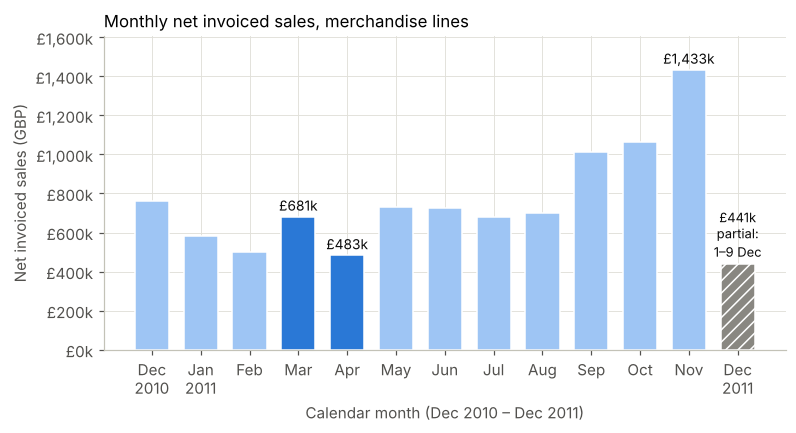

Interpretation: net sales fell from £680,582 in March 2011 to £482,901 in April 2011, the lowest complete month; the peak was £1,432,735 in November 2011.


In [11]:
labels = [p.strftime("%b\n%Y") if p.month in (12, 1) else p.strftime("%b") for p in monthly.index]
x = np.arange(len(monthly))
colors = [GRAY if not c else BLUE_LIGHT for c in monthly["complete"]]
for i, p in enumerate(monthly.index):
    if str(p) in ("2011-03", "2011-04"):
        colors[i] = BLUE
fig, ax = plt.subplots(figsize=(8, 3.7))
bars = ax.bar(x, monthly["net_sales"], color=colors, width=0.7, edgecolor="white", linewidth=1)
bars[-1].set_hatch("///"); bars[-1].set_edgecolor("white")
ax.set_xticks(x, labels); ax.yaxis.set_major_formatter(gbp_k)
ax.set_ylabel("Net invoiced sales (GBP)"); ax.set_xlabel("Calendar month (Dec 2010 – Dec 2011)")
ax.set_title("Monthly net invoiced sales, merchandise lines", loc="left")
for i, p in enumerate(monthly.index):
    if str(p) in ("2011-03", "2011-04", "2011-11"):
        ax.text(i, monthly["net_sales"].iloc[i] + 15000, f"£{monthly['net_sales'].iloc[i]/1000:,.0f}k",
                ha="center", va="bottom", fontsize=9, color=INK)
ax.text(len(x) - 1, monthly["net_sales"].iloc[-1] + 15000, f"£{monthly['net_sales'].iloc[-1]/1000:,.0f}k\npartial:\n1–9 Dec",
        ha="center", va="bottom", fontsize=8.5, color=INK, linespacing=1.1)
ax.set_ylim(0, monthly["net_sales"].max() * 1.12)
save(fig, "fig1_monthly_net_sales")
m, a = monthly.loc["2011-03", "net_sales"], monthly.loc["2011-04", "net_sales"]
print(f"Interpretation: net sales fell from £{m:,.0f} in March 2011 to £{a:,.0f} in April 2011, the lowest complete month; "
      f"the peak was £{monthly.loc['2011-11', 'net_sales']:,.0f} in November 2011.")

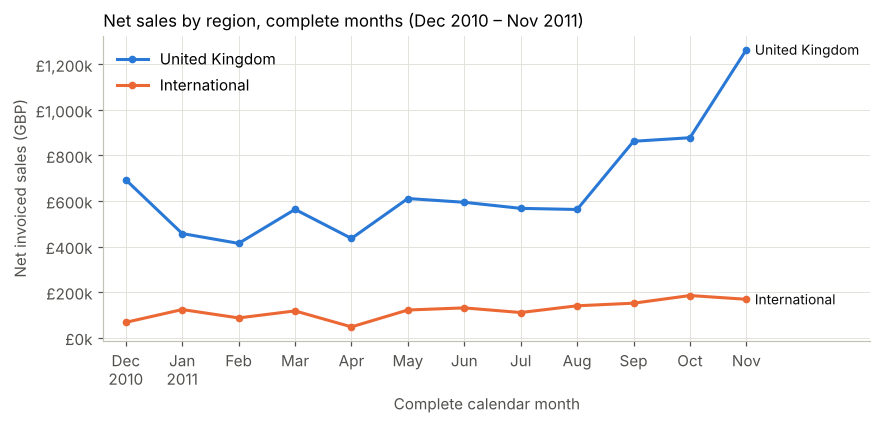

Region,International,United Kingdom,intl_share_%
Month,,,
2010-12,"67,267.40","693,056.51",8.85
2011-01,"123,368.81","457,038.08",21.26
2011-02,"86,605.24","413,905.09",17.30
2011-03,"117,430.66","563,151.65",17.25
2011-04,"47,309.08","435,592.13",9.80
2011-05,"121,414.65","610,829.53",16.58
2011-06,"130,698.54","594,292.49",18.03
2011-07,"110,294.98","567,660.22",16.27
2011-08,"139,899.70","562,684.28",19.91


Interpretation: the UK is 84% of complete-month net sales on average. International net sales were £117,431 in March 2011 and £47,309 in April 2011, their lowest month.


In [12]:
reg = (sales[sales["Month"].isin(complete.index)]
       .pivot_table(index="Month", columns="Region", values="LineValue", aggfunc="sum"))
fig, ax = plt.subplots(figsize=(9, 3.6))
xc = np.arange(len(reg))
for name, col in [("United Kingdom", BLUE), ("International", ORANGE)]:
    ax.plot(xc, reg[name], color=col, lw=2, marker="o", ms=4, label=name)
    ax.text(xc[-1] + 0.15, reg[name].iloc[-1], name, va="center", fontsize=9, color=INK)
ax.set_xticks(xc, [p.strftime("%b\n%Y") if p.month in (12, 1) else p.strftime("%b") for p in reg.index])
ax.yaxis.set_major_formatter(gbp_k); ax.set_xlim(-0.4, len(xc) + 1.2)
ax.set_ylabel("Net invoiced sales (GBP)"); ax.set_xlabel("Complete calendar month")
ax.set_title("Net sales by region, complete months (Dec 2010 – Nov 2011)", loc="left")
ax.legend(loc="upper left")
save(fig, "fig2_region_monthly")
reg["intl_share_%"] = reg["International"] / (reg["United Kingdom"] + reg["International"]) * 100
display(reg)
print(f"Interpretation: the UK is {100 - reg['intl_share_%'].mean():.0f}% of complete-month net sales on average. "
      f"International net sales were £{reg.loc['2011-03', 'International']:,.0f} in March 2011 and "
      f"£{reg.loc['2011-04', 'International']:,.0f} in April 2011, their lowest month.")
R.update(intl_share_avg=float(reg["intl_share_%"].mean()),
         intl_share_mar=float(reg.loc["2011-03", "intl_share_%"]), intl_share_apr=float(reg.loc["2011-04", "intl_share_%"]),
         intl_min_month=str(reg["International"].idxmin()))

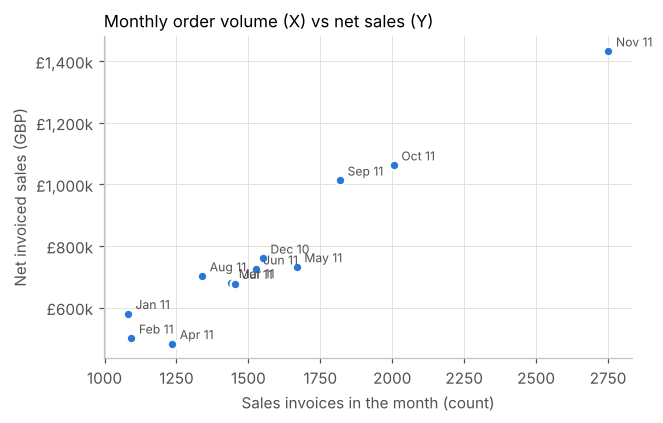

Pearson correlation, sales invoices vs net sales (12 complete months): r = 0.97
Interpretation: April 2011 had 1,235 sales invoices vs 1,440 in March 2011; months with more orders have higher net sales.


In [13]:
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.scatter(complete["sales_invoices"], complete["net_sales"], s=40, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
for p, row in complete.iterrows():
    ax.annotate(p.strftime("%b %y"), (row["sales_invoices"], row["net_sales"]), xytext=(5, 3),
                textcoords="offset points", fontsize=8, color=INK2)
ax.yaxis.set_major_formatter(gbp_k)
ax.set_xlabel("Sales invoices in the month (count)"); ax.set_ylabel("Net invoiced sales (GBP)")
ax.set_title("Monthly order volume (X) vs net sales (Y)", loc="left")
save(fig, "fig3_invoices_vs_sales")
r_inv = np.corrcoef(complete["sales_invoices"], complete["net_sales"])[0, 1]
print(f"Pearson correlation, sales invoices vs net sales (12 complete months): r = {r_inv:.2f}")
print(f"Interpretation: April 2011 had {complete.loc['2011-04', 'sales_invoices']:,} sales invoices vs "
      f"{complete.loc['2011-03', 'sales_invoices']:,} in March 2011; months with more orders have higher net sales.")
R["r_invoices_sales"] = float(r_inv)

**Comments by variable type.**
*Time (ordinal):* the months form a short series (12 complete points), so seasonality cannot be separated from
trend with only one year. *Country (nominal):* one category, the United Kingdom, dominates, so international
movements look small in total but can be large in relative terms (region chart above). *Counts (discrete):* the number of
sales invoices moves almost one-for-one with net sales (scatter chart above), which shows that order volume drives Y.
*GBP measures (continuous, right-skewed):* invoice values have a long upper tail (Step 6B).

## Step 6 – Select features and apply three descriptive methods

| Field | Kept? | Why it matters for the decision |
|---|---|---|
| `InvoiceDate` → Month, Day | yes | Defines the time series, complete months and invoice days |
| `Quantity`, `UnitPrice` → `LineValue` | yes | Build Y (signed GBP value) |
| `InvoiceNo` (+ `C` prefix) | yes | Separates sales from credits; groups lines into orders (method B) |
| `Country` → Region | yes | Explains *where* the change came from (method C) |
| `CustomerID` | yes (drill-down only) | Shows whether a country's change is one account or many; blanks kept |
| `StockCode` | scope filter only | Used to remove non-merchandise codes (R3) |
| `Description` | no | Free text; not needed for a monthly sales KPI |

The three methods are **A** time-series comparison, **B** distribution analysis of order values and
**C** country contribution analysis.

### Method A – Time-series comparison of adjacent complete months

*Why:* the management question is about change over time, so we compare each complete month with the month before it.
Changes are given in GBP (used for ranking) and in % (= change ÷ previous month). If the previous month is zero or
negative, the % is undefined and shown as "n/a".

In [14]:
def mom_changes(mt):
    c = mt[mt["complete"]].copy()
    c["prev_month"] = [str(p - 1) if (p - 1) in c.index else None for p in c.index]
    prev = c["net_sales"].shift(1).where([(p - 1) in c.index for p in c.index])
    c["change_gbp"] = c["net_sales"] - prev
    c["change_pct"] = np.where(prev > 0, c["change_gbp"] / prev.where(prev > 0) * 100, np.nan)  # zero/negative base -> n/a
    return c

mom = mom_changes(monthly)
show = mom[["prev_month", "net_sales", "change_gbp", "change_pct", "invoice_days", "net_per_invoice_day"]].copy()
show["change_pct"] = show["change_pct"].map(lambda v: "n/a" if pd.isna(v) else f"{v:+.1f}%")
display(show)

ranked = mom.dropna(subset=["change_gbp"]).sort_values("change_gbp")
worst = ranked.index[0]; prev_p = worst - 1
print("Largest declines (GBP):")
display(ranked[["prev_month", "change_gbp", "change_pct"]].head(3))
print(f"Largest absolute decline: {prev_p.strftime('%B %Y')} -> {worst.strftime('%B %Y')}: "
      f"{money(mom.loc[worst, 'change_gbp'])} ({mom.loc[worst, 'change_pct']:+.1f}%)")
print(f"December 2011 (1–9 Dec only, net £{monthly.loc['2011-12', 'net_sales']:,.0f}) is partial and NOT compared with November.")
R.update(worst_month=str(worst), prev_month=str(prev_p),
         worst_change=float(mom.loc[worst, "change_gbp"]), worst_pct=float(mom.loc[worst, "change_pct"]),
         second_month=str(ranked.index[1]), second_change=float(ranked["change_gbp"].iloc[1]),
         second_pct=float(ranked["change_pct"].iloc[1]),
         n_declines=int((ranked["change_gbp"] < 0).sum()), n_comparisons=int(len(ranked)),
         mom={str(k): {"change_gbp": float(v["change_gbp"]), "change_pct": float(v["change_pct"])}
              for k, v in ranked.iterrows()})

,prev_month,net_sales,change_gbp,change_pct,invoice_days,net_per_invoice_day
Month,,,,,,
2010-12,NaN,"760,323.91",NaN,n/a,20,"38,016.20"
2011-01,2010-12,"580,406.89","-179,917.02",-23.7%,24,"24,183.62"
2011-02,2011-01,"500,510.33","-79,896.56",-13.8%,24,"20,854.60"
2011-03,2011-02,"680,582.31","180,071.98",+36.0%,27,"25,206.75"
2011-04,2011-03,"482,901.21","-197,681.10",-29.0%,21,"22,995.30"
2011-05,2011-04,"732,244.18","249,342.97",+51.6%,25,"29,289.77"
2011-06,2011-05,"724,991.03","-7,253.15",-1.0%,26,"27,884.27"
2011-07,2011-06,"677,955.20","-47,035.83",-6.5%,26,"26,075.20"
2011-08,2011-07,"702,583.98","24,628.78",+3.6%,26,"27,022.46"


Largest declines (GBP):


,prev_month,change_gbp,change_pct
Month,,,
2011-04,2011-03,"-197,681.10",-29.05
2011-01,2010-12,"-179,917.02",-23.66
2011-02,2011-01,"-79,896.56",-13.77


Largest absolute decline: March 2011 -> April 2011: −£197,681 (-29.0%)
December 2011 (1–9 Dec only, net £441,367) is partial and NOT compared with November.


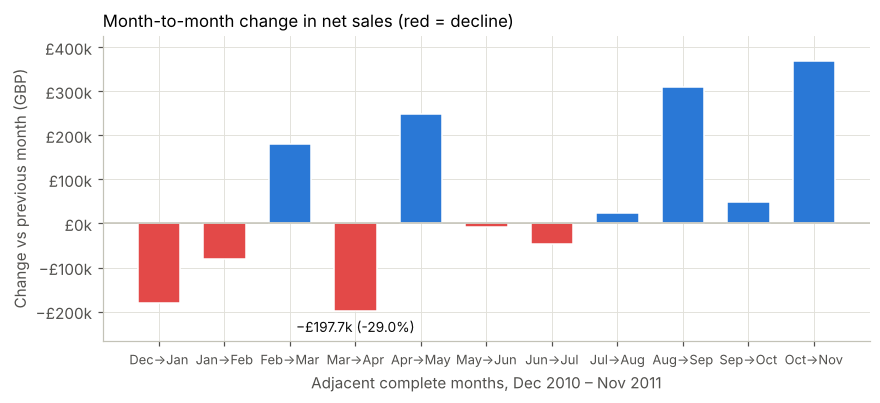

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ch = mom.dropna(subset=["change_gbp"])
ax.bar(np.arange(len(ch)), ch["change_gbp"], color=[RED if v < 0 else BLUE for v in ch["change_gbp"]],
       width=0.65, edgecolor="white")
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_xticks(np.arange(len(ch)), [f"{(p - 1).strftime('%b')}→{p.strftime('%b')}" for p in ch.index], fontsize=8.5)
ax.yaxis.set_major_formatter(gbp_k)
ax.set_ylabel("Change vs previous month (GBP)"); ax.set_xlabel("Adjacent complete months, Dec 2010 – Nov 2011")
ax.set_title("Month-to-month change in net sales (red = decline)", loc="left")
i = list(ch.index).index(worst)
ax.annotate(f"{money(ch.loc[worst, 'change_gbp']/1000, 1)}k ({ch.loc[worst, 'change_pct']:+.1f}%)", (i, ch.loc[worst, "change_gbp"]),
            xytext=(0, -14), textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.set_ylim(ch["change_gbp"].min() * 1.35, ch["change_gbp"].max() * 1.15)
save(fig, "fig4_mom_change")

In [16]:
# A.2 Coverage check: did April have fewer invoicing days than March?
a, b = monthly.loc[prev_p], monthly.loc[worst]
days_eff = (b["invoice_days"] - a["invoice_days"]) * a["net_per_invoice_day"]
rate_eff = b["invoice_days"] * (b["net_per_invoice_day"] - a["net_per_invoice_day"])
assert np.isclose(days_eff + rate_eff, b["net_sales"] - a["net_sales"])
d_prev = sorted(sales.loc[sales["Month"] == prev_p, "Day"].dt.day.unique())
d_worst = sorted(sales.loc[sales["Month"] == worst, "Day"].dt.day.unique())
cal = pd.date_range(worst.start_time, worst.end_time.normalize(), freq="D")
no_inv = [d for d in cal if d.day not in d_worst]
print(f"Invoice days: {prev_p} {int(a['invoice_days'])}, {worst} {int(b['invoice_days'])}")
print("Dates in", worst, "with no eligible invoice:", [d.strftime("%a %d %b") for d in no_inv])
print("Weekdays present in the whole dataset:", sorted(sales["InvoiceDate"].dt.day_name().unique()))
print(f"Net sales per invoice day: £{a['net_per_invoice_day']:,.0f} -> £{b['net_per_invoice_day']:,.0f} "
      f"({(b['net_per_invoice_day'] / a['net_per_invoice_day'] - 1) * 100:+.1f}%)")
print(f"Arithmetic split of the {money(b['net_sales'] - a['net_sales'])} change: six fewer invoice days valued at March's net sales per invoice day {money(days_eff)} "
      f"({days_eff / (b['net_sales'] - a['net_sales']) * 100:.0f}%), lower sales per invoice day {money(rate_eff)} "
      f"({rate_eff / (b['net_sales'] - a['net_sales']) * 100:.0f}%)")
print(f"Positive sales £{a['positive_sales']:,.0f} -> £{b['positive_sales']:,.0f} ({money(b['positive_sales'] - a['positive_sales'])}); "
      f"credits £{a['credit_magnitude']:,.0f} -> £{b['credit_magnitude']:,.0f} (+{money(b['credit_magnitude'] - a['credit_magnitude'])})")
R.update(days_prev=int(a["invoice_days"]), days_worst=int(b["invoice_days"]),
         no_invoice_dates=[d.strftime("%Y-%m-%d") for d in no_inv],
         perday_prev=float(a["net_per_invoice_day"]), perday_worst=float(b["net_per_invoice_day"]),
         perday_pct=float((b["net_per_invoice_day"] / a["net_per_invoice_day"] - 1) * 100),
         days_effect=float(days_eff), rate_effect=float(rate_eff),
         pos_prev=float(a["positive_sales"]), pos_worst=float(b["positive_sales"]),
         cred_prev=float(a["credit_magnitude"]), cred_worst=float(b["credit_magnitude"]),
         inv_prev=int(a["sales_invoices"]), inv_worst=int(b["sales_invoices"]))

# A.3 Partial December 2011: compare like-for-like with the same dates one year earlier
lfl = {}
for yr in (2010, 2011):
    s = sales[(sales["InvoiceDate"] >= f"{yr}-12-01") & (sales["InvoiceDate"] < f"{yr}-12-10")]
    lfl[yr] = (s["LineValue"].sum(), s["Day"].nunique())
print(f"\nLike-for-like 1–9 December: 2010 £{lfl[2010][0]:,.0f} ({lfl[2010][1]} invoice days) vs "
      f"2011 £{lfl[2011][0]:,.0f} ({lfl[2011][1]} invoice days): {(lfl[2011][0] / lfl[2010][0] - 1) * 100:+.1f}%")
R.update(lfl_2010=float(lfl[2010][0]), lfl_2011=float(lfl[2011][0]), lfl_pct=float((lfl[2011][0] / lfl[2010][0] - 1) * 100))

Invoice days: 2011-03 27, 2011-04 21
Dates in 2011-04 with no eligible invoice: ['Sat 02 Apr', 'Sat 09 Apr', 'Sat 16 Apr', 'Fri 22 Apr', 'Sat 23 Apr', 'Sun 24 Apr', 'Mon 25 Apr', 'Fri 29 Apr', 'Sat 30 Apr']
Weekdays present in the whole dataset: ['Friday', 'Monday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
Net sales per invoice day: £25,207 -> £22,995 (-8.8%)
Arithmetic split of the −£197,681 change: six fewer invoice days valued at March's net sales per invoice day −£151,241 (77%), lower sales per invoice day −£46,441 (23%)
Positive sales £691,258 -> £516,218 (−£175,039); credits £10,675 -> £33,317 (+£22,642)

Like-for-like 1–9 December: 2010 £402,364 (8 invoice days) vs 2011 £441,367 (8 invoice days): +9.7%


In [17]:
# A.4 Sensitivity: do material cleaning decisions change the answer?
def scope_result(mask, label):
    s = df[mask].copy()
    s["Month"] = s["InvoiceDate"].dt.to_period("M"); s["Day"] = s["InvoiceDate"].dt.normalize()
    t = monthly_table(s); mm = mom_changes(t).dropna(subset=["change_gbp"]).sort_values("change_gbp")
    return {"scope": label, "lines": len(s), "largest decline": f"{(mm.index[0] - 1).strftime('%b')}→{mm.index[0].strftime('%b %Y')}",
            "change_gbp": mm["change_gbp"].iloc[0], "change_pct": mm["change_pct"].iloc[0],
            "2nd largest": f"{(mm.index[1] - 1).strftime('%b')}→{mm.index[1].strftime('%b %Y')}",
            "gap_to_2nd_gbp": mm["change_gbp"].iloc[1] - mm["change_gbp"].iloc[0]}

base = df["Exclusion"] == "Retained"
sens = pd.DataFrame([
    scope_result(base, "Main scope (R1–R3)"),
    scope_result(base & ~dup_mask, "Main scope, repeated rows removed"),
    scope_result((df["UnitPrice"] > 0) & valid_sign, "Non-merchandise codes included"),
    scope_result(base & df["CustomerID"].notna(), "Only lines with a CustomerID"),
])
display(sens)
same = (sens["largest decline"] == sens["largest decline"].iloc[0]).all()
print("Largest decline identical under every scope:", same)
R["sensitivity"] = sens.to_dict(orient="records"); R["sensitivity_same"] = bool(same)

,scope,lines,largest decline,change_gbp,change_pct,2nd largest,gap_to_2nd_gbp
0,Main scope (R1–R3),536465,Mar→Apr 2011,"-197,681.10",-29.05,Dec→Jan 2011,"17,764.08"
1,"Main scope, repeated rows removed",531208,Mar→Apr 2011,"-197,267.28",-29.04,Dec→Jan 2011,"18,031.97"
2,Non-merchandise codes included,539392,Mar→Apr 2011,"-190,059.96",-27.82,Dec→Jan 2011,"1,103.20"
3,Only lines with a CustomerID,404879,Mar→Apr 2011,"-152,573.50",-26.56,Dec→Jan 2011,"75,221.24"


Largest decline identical under every scope: True


**Method A result.** Among the 11 comparisons of adjacent complete months, the largest GBP decline is
**March → April 2011: −£197,681 (−29.0%)**, followed by December 2010 → January 2011 (−£179,917, −23.7%).
April also had only 21 invoice days against 27 in March: no eligible invoice is dated 22–25 April or 29–30 April 2011
(Saturdays never appear in the data). Net sales per invoice day fell by only 8.8% (£25,207 → £22,995).
Valuing the six missing days at March's net sales per invoice day gives −£151,241, which corresponds arithmetically
to about 77% of the decline; lower sales per invoice day account for the other −£46,441. The 22–25 April dates coincide
with the 2011 Easter weekend and 29 April 2011 was a bank holiday for the royal wedding, but the records do not show
whether the business was closed, so the company's own trading calendar should be checked first. The same March → April result appears under all four
cleaning scopes. With non-merchandise codes included, however, January is only about £1.1k behind, so the ranking
of the two biggest falls is close and depends on scope.
Partial December 2011 is compared only with 1–9 December 2010 (+9.7%), never with full November.

*Limitation:* a month-to-month comparison cannot separate seasonality from a real problem, because one year of
data has no earlier April for comparison. The invoice-day split is arithmetic, not proof of cause.

### Method B – Distribution of order (invoice) values

*Why:* a monthly total can fall because there are **fewer orders** or because orders are **smaller**. The mean is
pulled up by a few very large wholesale orders, so the median, quartiles and the 95th percentile (P95) are used.
*Qualifying invoices:* non-credit invoices in the 12 complete months, valued as the sum of their eligible
merchandise lines (always positive).

In [18]:
inv = (sales[~sales["IsCredit"] & sales["Month"].isin(complete.index)]
       .groupby("InvoiceNo").agg(value=("LineValue", "sum"), Month=("Month", "first"),
                                 months=("Month", "nunique"), Country=("Country", "first")))
assert (inv["months"] == 1).all()  # no invoice spans two months
p95_all = inv["value"].quantile(0.95)
def dist(v):
    q = v.quantile([0.25, 0.5, 0.75, 0.95])
    return pd.Series({"invoices": len(v), "Q1": q[0.25], "median": q[0.5], "Q3": q[0.75], "P95": q[0.95],
                      "mean": v.mean(), "max": v.max(),
                      "large_orders(>12m P95)": int((v > p95_all).sum()),
                      "large_order_value": v[v > p95_all].sum(),
                      "share_of_value_from_large_%": v[v > p95_all].sum() / v.sum() * 100})
overall = dist(inv["value"])
by_month = inv.groupby("Month")["value"].apply(dist).unstack()
print(f"All {len(inv):,} qualifying invoices, Dec 2010 – Nov 2011:")
print(overall.apply(lambda v: f"{v:,.2f}"))
display(by_month.loc[[prev_p, worst]])
R.update(inv_n=int(overall["invoices"]), inv_q1=float(overall["Q1"]), inv_median=float(overall["median"]),
         inv_q3=float(overall["Q3"]), inv_p95=float(overall["P95"]), inv_mean=float(overall["mean"]),
         inv_max=float(overall["max"]), inv_large_share=float(overall["share_of_value_from_large_%"]),
         inv_by_month={str(p): {k: float(v) for k, v in by_month.loc[p].items()} for p in (prev_p, worst)})

All 18,957 qualifying invoices, Dec 2010 – Nov 2011:
invoices                          18,957.00
Q1                                   152.63
median                               302.72
Q3                                   484.40
P95                                1,505.73
mean                                 509.36
max                               77,183.60
large_orders(>12m P95)               948.00
large_order_value              3,502,857.83
share_of_value_from_large_%           36.28
dtype: str


,invoices,Q1,median,Q3,P95,mean,max,large_orders(>12m P95),large_order_value,share_of_value_from_large_%
Month,,,,,,,,,,
2011-03,"1,440.00",150.11,294.61,475.32,"1,464.55",480.04,"21,389.60",71.00,"232,008.78",33.56
2011-04,"1,235.00",151.53,300.25,451.59,"1,232.63",417.99,"21,535.90",42.00,"115,549.55",22.38


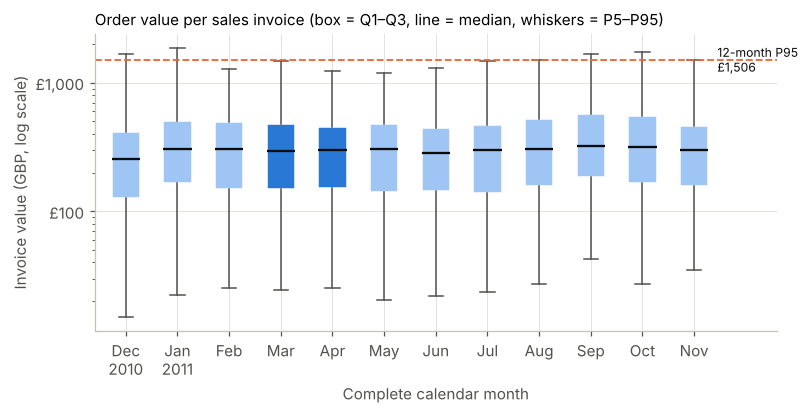

Interpretation: median order £295 in March vs £300 in April 2011 – the typical order did not shrink; large orders above £1,506 fell from 71 (£232,009) to 42 (£115,550).
2011-03 -> 2011-04 differences: sales invoices -205, median order +5.64 GBP, large orders -29, large-order value −£116,459, invoice days -6


In [19]:
fig, ax = plt.subplots(figsize=(8, 3.5))
data = [inv.loc[inv["Month"] == p, "value"].values for p in complete.index]
bp = ax.boxplot(data, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.55,
                medianprops=dict(color=INK, lw=1.5), whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
for patch, p in zip(bp["boxes"], complete.index):
    patch.set_facecolor(BLUE if p in (prev_p, worst) else BLUE_LIGHT); patch.set_edgecolor("white")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v:,.0f}"))
ax.set_xticks(range(1, len(complete) + 1), [p.strftime("%b\n%Y") if p.month in (12, 1) else p.strftime("%b") for p in complete.index])
ax.axhline(p95_all, color=ORANGE, lw=1.2, ls="--")
ax.text(len(complete) + 0.45, p95_all, f"12-month P95\n£{p95_all:,.0f}", va="center", fontsize=8, color=INK)
ax.set_xlim(0.4, len(complete) + 1.6)
ax.set_ylabel("Invoice value (GBP, log scale)"); ax.set_xlabel("Complete calendar month")
ax.set_title("Order value per sales invoice (box = Q1–Q3, line = median, whiskers = P5–P95)", loc="left", fontsize=10)
save(fig, "fig5_invoice_value_distribution")
bm = by_month
print(f"Interpretation: median order £{bm.loc[prev_p, 'median']:,.0f} in March vs £{bm.loc[worst, 'median']:,.0f} in April 2011 – "
      f"the typical order did not shrink; large orders above £{p95_all:,.0f} fell from {int(bm.loc[prev_p, 'large_orders(>12m P95)'])} "
      f"(£{bm.loc[prev_p, 'large_order_value']:,.0f}) to {int(bm.loc[worst, 'large_orders(>12m P95)'])} (£{bm.loc[worst, 'large_order_value']:,.0f}).")
diff = bm.loc[worst] - bm.loc[prev_p]
print(f"{prev_p} -> {worst} differences: sales invoices {diff['invoices']:+,.0f}, median order {diff['median']:+,.2f} GBP, "
      f"large orders {diff['large_orders(>12m P95)']:+,.0f}, large-order value {money(diff['large_order_value'])}, "
      f"invoice days {monthly.loc[worst, 'invoice_days'] - monthly.loc[prev_p, 'invoice_days']:+d}")

**Method B result.** Across 18,957 qualifying sales invoices, the typical order is about £303 (median), half of
all orders lie between £153 and £484, and the top 5% start at £1,506. These large orders contribute 36.3% of
all positive sales value. In March and April 2011 the **median order hardly moved (£295 → £300)**,
but April had 205 fewer sales invoices (1,440 → 1,235). Large orders above the 12-month P95 also fell from 71 to
42, and their value fell by about £116k (£232,009 → £115,550). The fall therefore came from fewer orders and fewer big orders, not from
smaller typical orders.

*Limitation:* invoice values describe orders, not customers. One wholesaler can place several large invoices,
and credit notes are not netted against the order they reverse.

### Method C – Country contribution to the largest decline

*Why:* management needs to know **where** the change came from. For each country:
contribution = net sales in April − net sales in March (signed GBP). Countries that appear in only one of the two
months are included with 0 for the missing month. `Unspecified` is shown as the unknown-country group.
All contributions must add up to the total monthly change.

In [20]:
pair = sales[sales["Month"].isin([prev_p, worst])].copy()
pair["Country"] = pair["Country"].replace({"Unspecified": "Unspecified (unknown)"})
cc = pair.pivot_table(index="Country", columns="Month", values="LineValue", aggfunc="sum", fill_value=0.0)
cc.columns = [str(c) for c in cc.columns]
cc = cc.rename(columns={str(prev_p): "prev", str(worst): "worst"})
cc["contribution_gbp"] = cc["worst"] - cc["prev"]
cc["share_of_change_%"] = cc["contribution_gbp"] / cc["contribution_gbp"].sum() * 100
cc["in_one_month_only"] = (cc["prev"] == 0) | (cc["worst"] == 0)
cc = cc.sort_values("contribution_gbp")
total_change = monthly.loc[worst, "net_sales"] - monthly.loc[prev_p, "net_sales"]
assert np.isclose(cc["contribution_gbp"].sum(), total_change), "Country contributions do not reconcile"
print(f"Countries in either month: {len(cc)} | sum of contributions {money(cc['contribution_gbp'].sum(), 2)} "
      f"= total change {money(total_change, 2)}  ✔")
print("Largest downward contributions:"); display(cc.head(8))
print("Largest offsets (increases):"); display(cc.tail(5).iloc[::-1])
print("Countries present in only one of the two months:", ", ".join(cc.index[cc["in_one_month_only"]]))
cc.to_csv(OUT / "country_contributions.csv")

Countries in either month: 32 | sum of contributions −£197,681.10 = total change −£197,681.10  ✔
Largest downward contributions:


,prev,worst,contribution_gbp,share_of_change_%,in_one_month_only
Country,,,,,
United Kingdom,"563,151.65","435,592.13","-127,559.52",64.53,False
Netherlands,"22,206.49","2,886.56","-19,319.93",9.77,False
Australia,"17,055.29",-16.60,"-17,071.89",8.64,False
EIRE,"18,283.23","7,270.50","-11,012.73",5.57,False
France,"13,616.90","3,766.21","-9,850.69",4.98,False
Denmark,"3,978.99",0.00,"-3,978.99",2.01,True
Sweden,"4,500.58",649.10,"-3,851.48",1.95,False
Finland,"4,853.42","1,346.81","-3,506.61",1.77,False


Largest offsets (increases):


,prev,worst,contribution_gbp,share_of_change_%,in_one_month_only
Country,,,,,
Japan,5.51,"4,871.83","4,866.32",-2.46,False
Singapore,0.00,"2,118.74","2,118.74",-1.07,True
Hong Kong,0.00,"1,539.64","1,539.64",-0.78,True
Brazil,0.00,"1,143.60","1,143.60",-0.58,True
Iceland,0.00,636.25,636.25,-0.32,True


Countries present in only one of the two months: Denmark, Norway, Canada, Czech Republic, Saudi Arabia, Israel, European Community, Unspecified (unknown), USA, Iceland, Brazil, Hong Kong, Singapore


In [21]:
# Region view, also per invoice day, because April had fewer invoice days
rg = pair.groupby(["Region", "Month"]).agg(net=("LineValue", "sum"), days=("Day", "nunique")).unstack("Month")
reg_tab = pd.DataFrame({
    "net_prev": rg[("net", prev_p)], "net_worst": rg[("net", worst)],
    "change_gbp": rg[("net", worst)] - rg[("net", prev_p)],
    "change_%": (rg[("net", worst)] / rg[("net", prev_p)] - 1) * 100,
    "share_of_change_%": (rg[("net", worst)] - rg[("net", prev_p)]) / total_change * 100,
    "per_day_prev": rg[("net", prev_p)] / monthly.loc[prev_p, "invoice_days"],
    "per_day_worst": rg[("net", worst)] / monthly.loc[worst, "invoice_days"]})
reg_tab["per_day_change_%"] = (reg_tab["per_day_worst"] / reg_tab["per_day_prev"] - 1) * 100
display(reg_tab)

# Drill-down: accounts behind the four largest international declines
top_intl = [c for c in cc.index if c != "United Kingdom"][:4]
acct = (pair[pair["Country"].isin(top_intl)]
        .assign(Customer=lambda d: d["CustomerID"].astype("string").fillna("unknown"))
        .pivot_table(index=["Country", "Customer"], columns="Month", values="LineValue", aggfunc="sum", fill_value=0.0))
acct.columns = ["prev", "worst"]; acct["change_gbp"] = acct["worst"] - acct["prev"]
acct = acct.sort_values("change_gbp")
display(acct.head(8))
top4 = cc.loc[top_intl, "contribution_gbp"].sum()
print(f"Top-4 international countries {top_intl}: {money(top4)} ({top4 / total_change * 100:.0f}% of the decline)")
R.update(total_change=float(total_change), n_countries_pair=int(len(cc)),
         contrib={c: float(v) for c, v in cc["contribution_gbp"].items()},
         contrib_prev={c: float(v) for c, v in cc["prev"].items()}, contrib_worst={c: float(v) for c, v in cc["worst"].items()},
         one_month_only=list(cc.index[cc["in_one_month_only"]]),
         region={r: {k: float(v) for k, v in reg_tab.loc[r].items()} for r in reg_tab.index},
         top_intl=top_intl, top_intl_sum=float(top4),
         top_accounts=[{"country": i[0], "customer": i[1], "prev": float(r["prev"]), "worst": float(r["worst"]),
                        "change": float(r["change_gbp"])} for i, r in acct.head(5).iterrows()])

,net_prev,net_worst,change_gbp,change_%,share_of_change_%,per_day_prev,per_day_worst,per_day_change_%
Region,,,,,,,,
International,"117,430.66","47,309.08","-70,121.58",-59.71,35.47,"4,349.28","2,252.81",-48.20
United Kingdom,"563,151.65","435,592.13","-127,559.52",-22.65,64.53,"20,857.47","20,742.48",-0.55


,,prev,worst,change_gbp
Country,Customer,,,
Netherlands,14646,"21,327.40","2,886.56","-18,440.84"
Australia,12415,"16,558.14",-425.00,"-16,983.14"
EIRE,14156,"9,689.67","2,898.18","-6,791.49"
France,12678,"3,243.13",0.00,"-3,243.13"
EIRE,14911,"6,653.05","4,372.32","-2,280.73"
France,12731,"2,350.46",177.00,"-2,173.46"
EIRE,14016,"1,477.56",0.00,"-1,477.56"
France,12683,"1,428.08",0.00,"-1,428.08"


Top-4 international countries ['Netherlands', 'Australia', 'EIRE', 'France']: −£57,255 (29% of the decline)


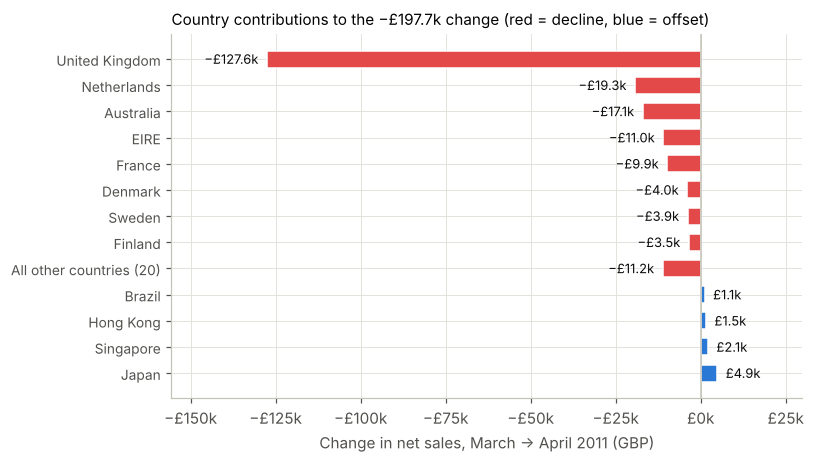

UK: whole month £563,152 -> £435,592 (-22.7%); per invoice day £563,152/27 = £20,857 -> £435,592/21 = £20,742 (-0.6%); share of total change 65%
International: whole month £117,431 -> £47,309 (-59.7%); per invoice day £117,431/27 = £4,349 -> £47,309/21 = £2,253 (-48.2%); share of total change 35%


In [22]:
show_n = 8
down = cc.head(show_n); up = cc[cc["contribution_gbp"] > 0].tail(4)
rest = cc.drop(down.index.union(up.index))
plot = pd.concat([down["contribution_gbp"],
                  pd.Series({f"All other countries ({len(rest)})": rest["contribution_gbp"].sum()}),
                  up["contribution_gbp"]])
fig, ax = plt.subplots(figsize=(7.4, 4.3))
yy = np.arange(len(plot))[::-1]
ax.barh(yy, plot.values, color=[RED if v < 0 else BLUE for v in plot.values], height=0.65, edgecolor="white")
ax.set_yticks(yy, plot.index, fontsize=9)
ax.axvline(0, color="#c3c2b7", lw=1)
ax.xaxis.set_major_formatter(gbp_k)
for yv, v in zip(yy, plot.values):
    ax.text(v + (-2500 if v < 0 else 2500), yv, f"{money(v/1000, 1)}k", va="center", ha="right" if v < 0 else "left", fontsize=8.5, color=INK)
ax.set_xlim(plot.min() * 1.22, max(plot.max(), 0) + 25000)
ax.set_xlabel(f"Change in net sales, {prev_p.strftime('%B')} → {worst.strftime('%B %Y')} (GBP)")
ax.set_title(f"Country contributions to the {money(total_change/1000, 1)}k change (red = decline, blue = offset)", loc="left", fontsize=10)
save(fig, "fig6_country_contributions")
uk = reg_tab.loc["United Kingdom"]; it = reg_tab.loc["International"]
d0, d1 = int(monthly.loc[prev_p, "invoice_days"]), int(monthly.loc[worst, "invoice_days"])
for name, r in (("UK", uk), ("International", it)):
    print(f"{name}: whole month {money(r['net_prev'])} -> {money(r['net_worst'])} ({r['change_%']:+.1f}%); "
          f"per invoice day {money(r['net_prev'])}/{d0} = {money(r['per_day_prev'])} -> {money(r['net_worst'])}/{d1} = "
          f"{money(r['per_day_worst'])} ({r['per_day_change_%']:+.1f}%); share of total change {r['share_of_change_%']:.0f}%")

**Method C result.** All 32 countries reconcile exactly to the −£197,681 change. The United Kingdom contributed
−£127,560 (65%): its whole-month net sales fell 22.7%, but per invoice day they changed by only −0.6%
(£563,152 / 27 days = £20,857 → £435,592 / 21 days = £20,742). International customers contributed −£70,122 (35%)
even though they were only 17% of March sales: their whole-month net sales fell 59.7%, and per invoice day they fell
48.2% (£4,349 → £2,253, same 27- and 21-day denominators). Four countries – the Netherlands (−£19,320), Australia (−£17,072),
EIRE (−£11,013) and France (−£9,851) – account for −£57,255, or 29% of the total decline. Most of this came from a few large accounts that ordered less in April
(e.g., Netherlands customer 14646: £21,327 → £2,887; Australia customer 12415: £16,558 → −£425).
Small offsets came from Japan (+£4,866), Singapore (+£2,119) and Hong Kong (+£1,540).

*Limitation:* a country contribution shows where the money moved, not why. One large account can drive a whole
country, and credit notes are dated when issued, not when the original sale happened.

In [23]:
methods = pd.DataFrame([
    ["A. Time-series comparison", "Question is about change between adjacent complete months",
     f"{prev_p.strftime('%b')}→{worst.strftime('%b %Y')}: {money(R['worst_change'])} ({R['worst_pct']:+.1f}%); per invoice day {R['perday_pct']:+.1f}%",
     "Cannot separate seasonality from a real problem with one year of data"],
    ["B. Distribution analysis", "Separates 'fewer orders' from 'smaller orders'; robust to outliers",
     f"Median order £{R['inv_by_month'][str(prev_p)]['median']:,.0f}→£{R['inv_by_month'][str(worst)]['median']:,.0f}; "
     f"sales invoices {R['inv_prev']:,}→{R['inv_worst']:,}",
     "Invoice ≠ customer; credits not matched to original orders"],
    ["C. Country contribution", "Shows where the change came from; sums exactly to the total",
     f"UK {money(R['region']['United Kingdom']['change_gbp'])} (month {R['region']['United Kingdom']['change_%']:+.1f}%, "
     f"per invoice day {R['region']['United Kingdom']['per_day_change_%']:+.1f}%); International "
     f"{money(R['region']['International']['change_gbp'])} (month {R['region']['International']['change_%']:+.1f}%, "
     f"per invoice day {R['region']['International']['per_day_change_%']:+.1f}%)",
     "Shows where, not why; a few accounts can dominate a country"],
], columns=["Method", "Why chosen", "Computed result", "Limitation"])
display(methods)

,Method,Why chosen,Computed result,Limitation
0,A. Time-series comparison,Question is about change between adjacent comp...,"Mar→Apr 2011: −£197,681 (-29.0%); per invoice ...",Cannot separate seasonality from a real proble...
1,B. Distribution analysis,Separates 'fewer orders' from 'smaller orders'...,"Median order £295→£300; sales invoices 1,440→1...",Invoice ≠ customer; credits not matched to ori...
2,C. Country contribution,Shows where the change came from; sums exactly...,"UK −£127,560 (month -22.7%, per invoice day -0...","Shows where, not why; a few accounts can domin..."


## Step 7 – Executive summary and introduction

**Company and data.** The client is the unnamed UK-based, registered, non-store online retailer described by
UCI and by Chen, Sain & Guo (2012). It sells mainly unique all-occasion gifts, and many of its customers are
wholesalers. The dataset contains all of its transactions between 1 December 2010 and 9 December 2011
(541,909 invoice lines, 38 countries). Since the data is the company's own invoice log, it can show where sales
rose and fell. It cannot show the reasons.

**Executive summary.** Management believes sales KPIs are below target (issue 1(b)(ii)). Across 12 complete
months, the largest month-to-month fall in net invoiced merchandise sales was **March → April 2011: −£197,681
(−29.0%)**, from £680,582 to £482,901. April had six fewer days with recorded invoices (21 vs 27). Valued at March's
net sales per invoice day, those six days correspond arithmetically to about 77% of the decline (−£151,241); the records
do not show why no invoices were recorded on them. On the same two bases, UK net sales fell 22.7% for the whole month
but only 0.6% per invoice day, while international net sales fell 59.7% for the whole month and 48.2% per invoice day.
A few large accounts in the Netherlands, Australia, EIRE and France ordered less in April (−£57,255 together). The
typical order size did not change (median about £300).
**Proposed action:** the sales team should first check the April trading calendar and then review the international
wholesale accounts that ordered less in April. Net sales per invoice day for UK and international customers should be
tracked as a monthly KPI.

In [24]:
key = pd.Series({
    "Raw invoice lines": f"{R['raw_rows']:,}",
    "Retained / excluded lines": f"{R['retained_rows']:,} / {R['excluded_rows']:,}",
    "Largest complete-month decline": f"{R['prev_month']} -> {R['worst_month']}: {money(R['worst_change'])} ({R['worst_pct']:+.1f}%)",
    "Invoice days (Mar / Apr)": f"{R['days_prev']} / {R['days_worst']}",
    "Net sales per invoice day change": f"{R['perday_pct']:+.1f}%",
    "UK change: GBP, whole-month %, per-invoice-day %": f"{money(R['region']['United Kingdom']['change_gbp'])}, {R['region']['United Kingdom']['change_%']:+.1f}%, {R['region']['United Kingdom']['per_day_change_%']:+.1f}%",
    "International change: GBP, whole-month %, per-invoice-day %": f"{money(R['region']['International']['change_gbp'])}, {R['region']['International']['change_%']:+.1f}%, {R['region']['International']['per_day_change_%']:+.1f}%",
    "Credit-note lines raw / retained": f"{R['credit_lines_raw']:,} / {R['retained_credit_lines']:,}",
    "Top-4 international countries": f"{', '.join(R['top_intl'])}: {money(R['top_intl_sum'])}",
    "Median order Mar / Apr": f"£{R['inv_by_month'][R['prev_month']]['median']:,.0f} / £{R['inv_by_month'][R['worst_month']]['median']:,.0f}",
})
print(key.to_string())

Raw invoice lines                                                                                     541,909
Retained / excluded lines                                                                     536,465 / 5,444
Largest complete-month decline                                         2011-03 -> 2011-04: −£197,681 (-29.0%)
Invoice days (Mar / Apr)                                                                              27 / 21
Net sales per invoice day change                                                                        -8.8%
UK change: GBP, whole-month %, per-invoice-day %                                     −£127,560, -22.7%, -0.6%
International change: GBP, whole-month %, per-invoice-day %                          −£70,122, -59.7%, -48.2%
Credit-note lines raw / retained                                                                9,288 / 8,704
Top-4 international countries                                  Netherlands, Australia, EIRE, France: −£57,255
Median ord

## Step 8 – Challenge / problem statement

**Problem.** Sales and KPIs are reported to be far below target, and management must decide within three weeks.
The real targets are not in the data, so this analysis uses the **preceding complete month as a historical
benchmark**. KPI = monthly net invoiced merchandise sales (GBP). Period = the 12 complete months from
December 2010 to November 2011 (December 2011 is partial).

**Why it matters.** If the company misreads a calendar effect as a demand problem, or the reverse, it will take the
wrong action. It could change products or prices when the decline is concentrated in a few accounts that ordered
less. Management therefore needs to know *where* sales were lower before it acts.

**What the records can establish.** When sales fell, by how much, in which countries and accounts, and whether the
cause was fewer orders, smaller orders or more credits. **What they cannot establish:** targets, margins or profit,
or why customers changed their behaviour. Those need input from the sales team and from customers.

## Step 9 – Solution statement and implementation plan

**Completed analysis (this notebook).** Cleaned and reconciled the full UCI log, built the monthly net-sales KPI,
and applied three descriptive methods (time-series comparison, order-value distribution, country contribution).
All three point the same way: the March → April 2011 fall coincides with fewer days with recorded invoices and with
lower international wholesale orders. The median order size did not change.

**Priority recommendation.** *The Head of Sales, with the international account managers, should review the
international wholesale accounts that ordered less in April 2011, starting with the four largest country contributors
(Netherlands, Australia, EIRE, France). Before that, Finance should confirm the April trading calendar.* The timeline
below is a proposed management schedule, not a completed result.

| When | Who | What | Output |
|---|---|---|---|
| Week 1 | Finance + Sales operations | Confirm whether 22–25 and 29–30 April 2011 were non-trading days. List April credit notes (£33,317 vs £10,675 in March) | Calendar-adjusted April baseline |
| Week 2 | Head of Sales + account managers | Contact the accounts that ordered less (e.g., NL 14646, AU 12415, EIRE 14156/14911). Record why April orders were lower (stock, price, timing, other) | Account-by-account reasons |
| Week 3 | Executive management | Decide on recovery actions per account. Approve the KPI below | Decision memo |
| Monthly, from then on | Sales operations | Review the KPI on the first working day of each month | KPI dashboard |

**Metric to monitor:** net invoiced sales **per invoice day**, split UK vs international, with credit
magnitude as % of positive sales as a supporting check.

**Proposed vs proven.** The recommendation is a proposed business action. Any benefit (recovered accounts,
better forecasts) is expected but **not measured** here. It should be confirmed with the same KPI in later months.

In [25]:
R["generated_with"] = {"python": platform.python_version(), "pandas": pd.__version__,
                       "numpy": np.__version__, "matplotlib": matplotlib.__version__}
with open(OUT / "results.json", "w") as f:
    json.dump(R, f, indent=2, default=str)
print("Saved:", OUT / "results.json", "and", len(list(FIG.glob('*.png'))), "figures in", FIG)

Saved: outputs/results.json and 6 figures in outputs/figures


### References
1. Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33
2. Chen, D., Sain, S. L., & Guo, K. (2012). Data mining for the online retail industry: A case study of RFM
   model-based customer segmentation using data mining. *Journal of Database Marketing & Customer Strategy
   Management, 19*(3), 197–208. https://doi.org/10.1057/dbm.2012.17
3. GOV.UK (2010). *PM welcomes announcement of date for Royal Wedding* (29 April 2011 declared a bank holiday).
   https://www.gov.uk/government/news/pm-welcomes-announcement-of-date-for-royal-wedding